In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset manzili
data_path = 'bank+marketing/bank-full.csv'

# Datasetni o'qish
df = pd.read_csv(data_path, sep=';')

df.describe()


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [19]:
# 1. GroupBy yordamida guruhlash

group_result = df.groupby(
    ['job', 'marital', 'education', 'housing']
).agg({
    'age': ['mean', 'count', 'std'],
    'balance': ['mean', 'count', 'std'],
    'duration': ['mean', 'count', 'std'],
    'campaign': ['mean', 'count', 'std']
})

print(group_result.round(2))

                                      age               balance        \
                                     mean count    std     mean count   
job     marital  education housing                                      
admin.  divorced primary   no       50.29     7   7.93   318.43     7   
                           yes      47.35    23   8.52  1458.96    23   
                 secondary no       44.15   217   9.05  1113.02   217   
                           yes      42.09   431   7.97   739.75   431   
                 tertiary  no       41.53    17   9.76  1257.18    17   
...                                   ...   ...    ...      ...   ...   
unknown single   secondary no       37.73    22  10.99  1102.77    22   
                           yes      39.00     2   2.83   351.50     2   
                 tertiary  no       36.55    11   7.10  2647.27    11   
                 unknown   no       40.43    23   6.98  1817.78    23   
                           yes      31.00     2   8

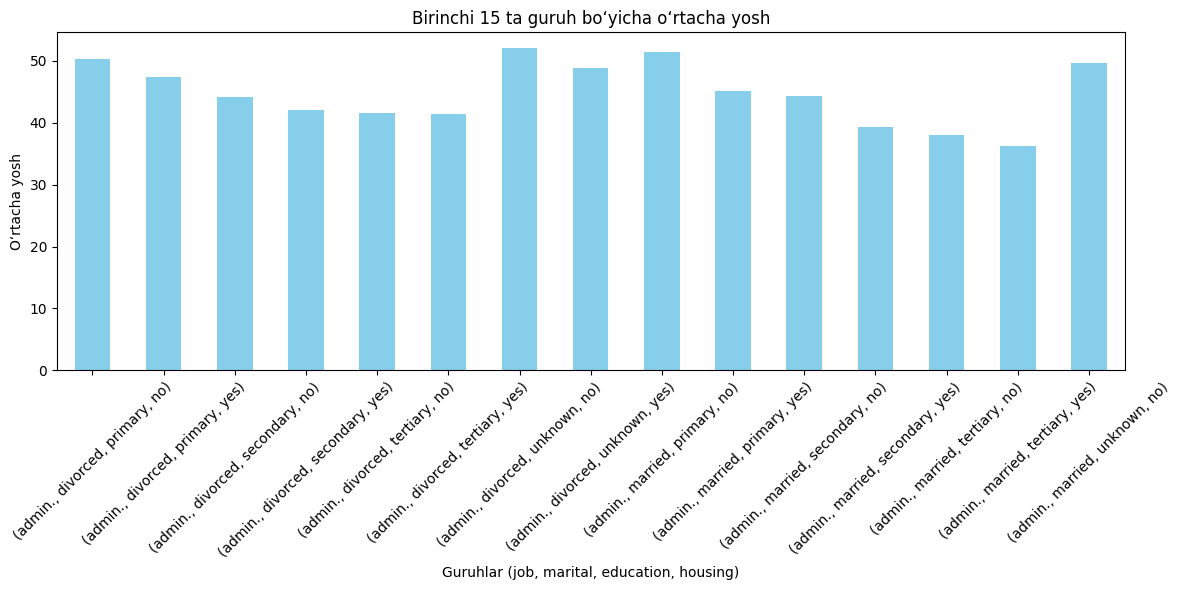

In [ ]:
# 1.1. Guruhlar bo‘yicha o‘rtacha yoshni ajratib olish

age_data = group_result['age']['mean']

# Birinchi 15 ta guruhni grafikda ko‘rsatish
age_data.head(15).plot(
    kind='bar',
    figsize=(12, 6),
    color='skyblue'
)

plt.title('Birinchi 15 ta guruh bo‘yicha o‘rtacha yosh')
plt.xlabel('Guruhlar (job, marital, education, housing)')
plt.ylabel('O‘rtacha yosh')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

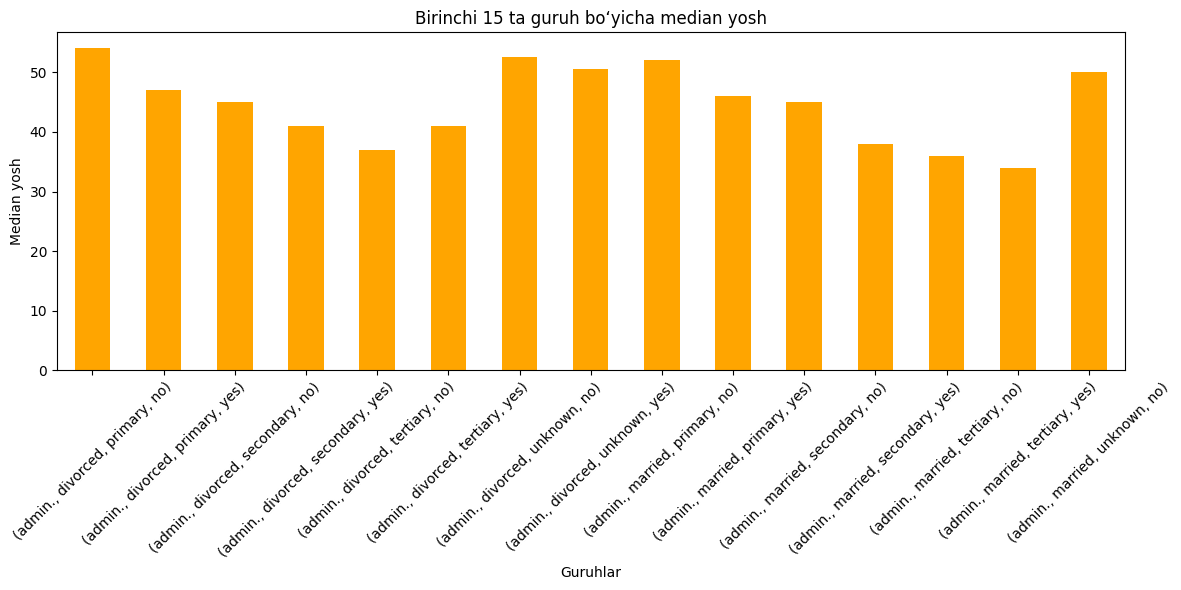

In [29]:
median_data = group_result['age']['median']

median_data.head(15).plot(
    kind='bar',
    figsize=(12, 6),
    color='orange'
)

plt.title('Birinchi 15 ta guruh bo‘yicha median yosh')
plt.xlabel('Guruhlar')
plt.ylabel('Median yosh')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# 2. Pivot jadval yaratish

pivot_table = pd.pivot_table(
    df,
    values='balance',
    index='job',
    columns='marital',
    aggfunc='mean'
)

print(pivot_table.round(2))

marital        divorced  married   single
job                                      
admin.           878.33  1281.41  1020.74
blue-collar      820.81  1113.17  1056.11
entrepreneur    1155.98  1643.39  1248.24
housemaid       1573.22  1248.17  2074.74
management      1618.07  1828.16  1700.22
retired         1507.84  2140.10  1360.39
self-employed   2426.35  1644.95  1410.37
services         834.30  1088.85   887.32
student         1101.00  1164.80  1403.75
technician       924.05  1307.40  1283.94
unemployed      1409.64  1568.63  1484.08
unknown         1706.29  1788.13  1741.79


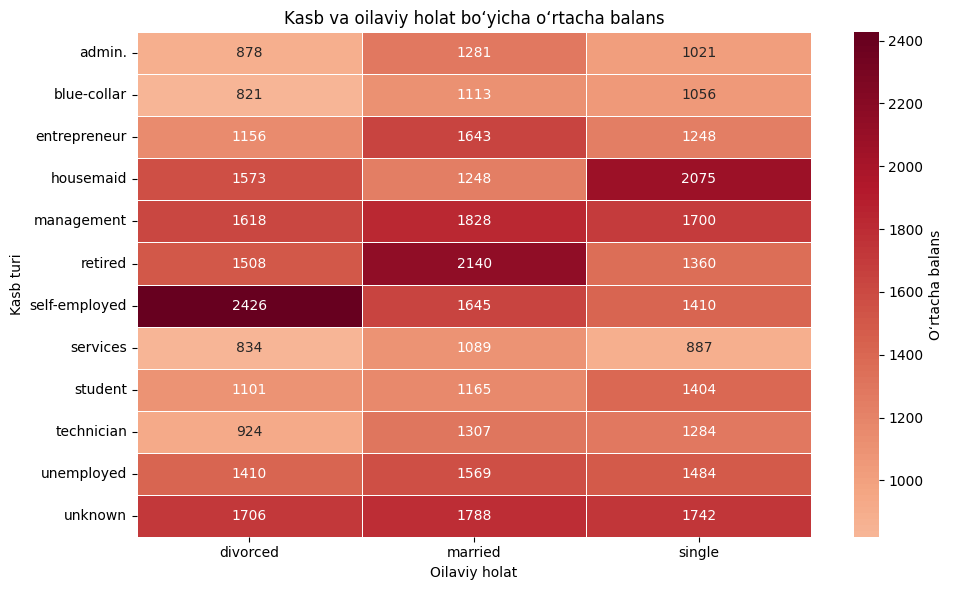

In [10]:
# 3. Pivot jadvalni Heatmap yordamida vizualizatsiya qilish

plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot_table.head(15),
    annot=True,
    fmt='.0f',
    cmap='RdBu_r',
    linewidths=0.5,
    center=0,
    cbar_kws={'label': 'O‘rtacha balans'}
)

plt.title('Kasb va oilaviy holat bo‘yicha o‘rtacha balans')
plt.xlabel('Oilaviy holat')
plt.ylabel('Kasb turi')

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [11]:
# 4. Maqsadli o'zgaruvchi (y) bo'yicha Heatmap

df['subscribed'] = (df['y'] == 'yes').astype(int)

pivot_target = pd.pivot_table(
    df,
    values='subscribed',
    index='job',
    columns='education',
    aggfunc='mean'
) * 100

print(pivot_table.round(2))

marital        divorced  married   single
job                                      
admin.           878.33  1281.41  1020.74
blue-collar      820.81  1113.17  1056.11
entrepreneur    1155.98  1643.39  1248.24
housemaid       1573.22  1248.17  2074.74
management      1618.07  1828.16  1700.22
retired         1507.84  2140.10  1360.39
self-employed   2426.35  1644.95  1410.37
services         834.30  1088.85   887.32
student         1101.00  1164.80  1403.75
technician       924.05  1307.40  1283.94
unemployed      1409.64  1568.63  1484.08
unknown         1706.29  1788.13  1741.79


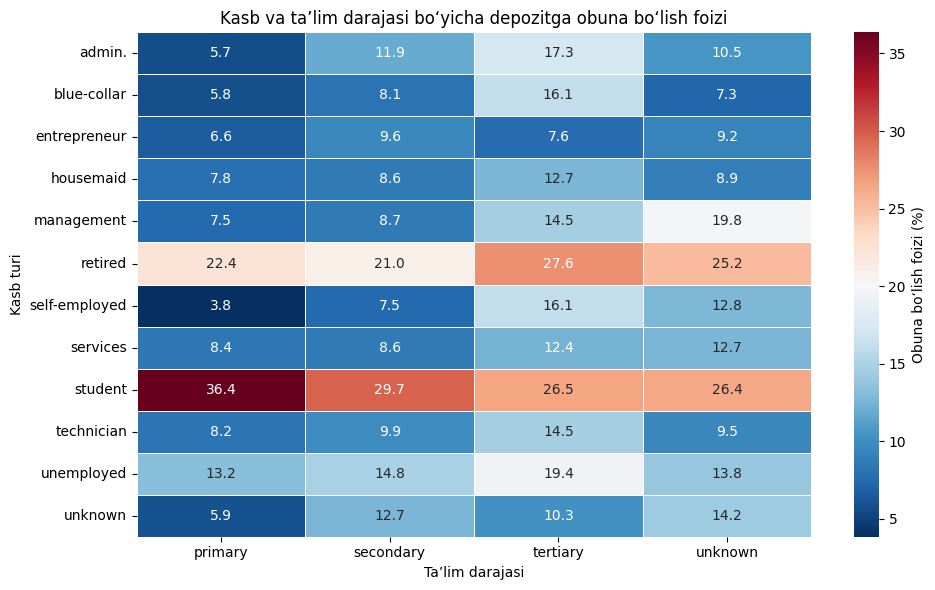

In [12]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot_target.head(15),
    annot=True,
    fmt='.1f',
    cmap='RdBu_r',
    linewidths=0.5,
    cbar_kws={'label': 'Obuna bo‘lish foizi (%)'}
)

plt.title('Kasb va ta’lim darajasi bo‘yicha depozitga obuna bo‘lish foizi')
plt.xlabel('Ta’lim darajasi')
plt.ylabel('Kasb turi')

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [13]:
# 5.1. Uzluksiz va miqdoriy o‘zgaruvchilar

numeric_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Sonli o‘zgaruvchilar:")
print(numeric_columns)

Sonli o‘zgaruvchilar:
Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous',
       'subscribed'],
      dtype='object')


In [14]:
# 5.2. Kategorik o‘zgaruvchilar

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print("Kategorik o‘zgaruvchilar:")
print(categorical_columns)

Kategorik o‘zgaruvchilar:
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'y'],
      dtype='object')


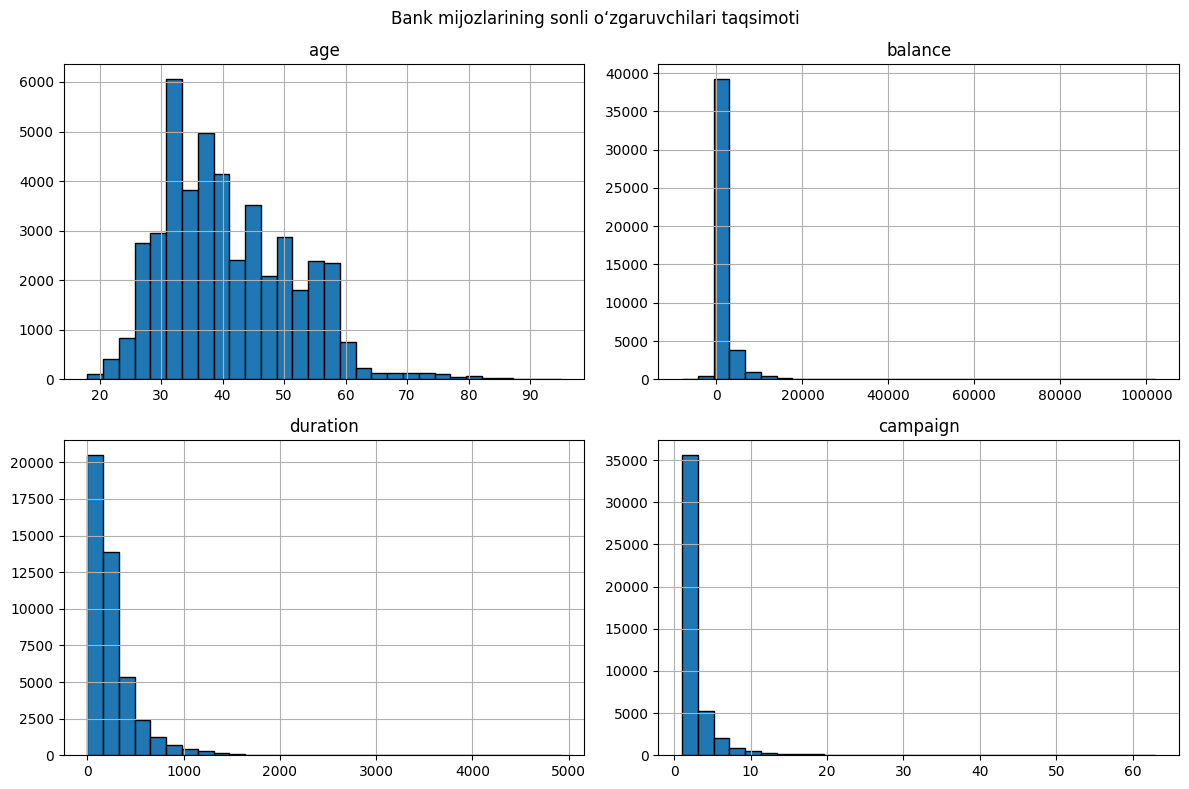

In [ ]:
# 5.3. O‘zgaruvchilarni grafikda taqqoslash

# Uzluksiz o‘zgaruvchilar taqsimoti

df[['age', 'balance', 'duration', 'campaign']].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Bank mijozlarining sonli o‘zgaruvchilari taqsimoti')
plt.tight_layout()
plt.show()

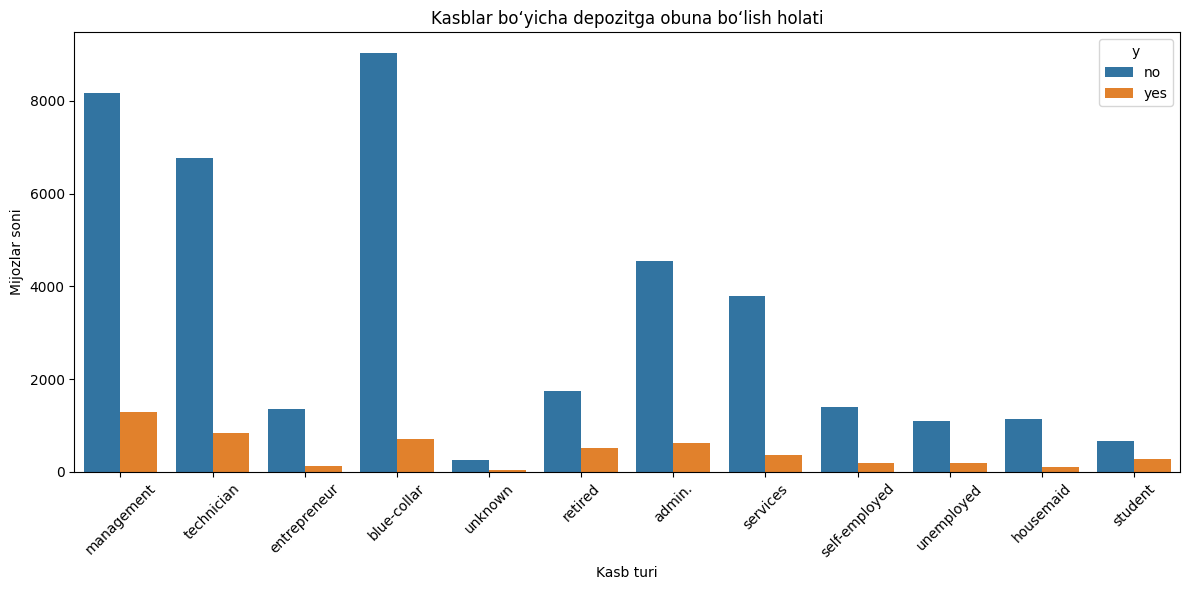

In [16]:
# Kategorik o‘zgaruvchilar

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='job',
    hue='y'
)

plt.title('Kasblar bo‘yicha depozitga obuna bo‘lish holati')
plt.xlabel('Kasb turi')
plt.ylabel('Mijozlar soni')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
# 6. Korrelatsiya

# Sonli ustunlarni ajratib olish
numeric_df = df.select_dtypes(include='number')

# Korrelatsiya matritsasini hisoblash
correlation_matrix = numeric_df.corr(method='pearson')

print(correlation_matrix.round(2))

             age  balance   day  duration  campaign  pdays  previous  \
age         1.00     0.10 -0.01     -0.00      0.00  -0.02      0.00   
balance     0.10     1.00  0.00      0.02     -0.01   0.00      0.02   
day        -0.01     0.00  1.00     -0.03      0.16  -0.09     -0.05   
duration   -0.00     0.02 -0.03      1.00     -0.08  -0.00      0.00   
campaign    0.00    -0.01  0.16     -0.08      1.00  -0.09     -0.03   
pdays      -0.02     0.00 -0.09     -0.00     -0.09   1.00      0.45   
previous    0.00     0.02 -0.05      0.00     -0.03   0.45      1.00   
subscribed  0.03     0.05 -0.03      0.39     -0.07   0.10      0.09   

            subscribed  
age               0.03  
balance           0.05  
day              -0.03  
duration          0.39  
campaign         -0.07  
pdays             0.10  
previous          0.09  
subscribed        1.00  


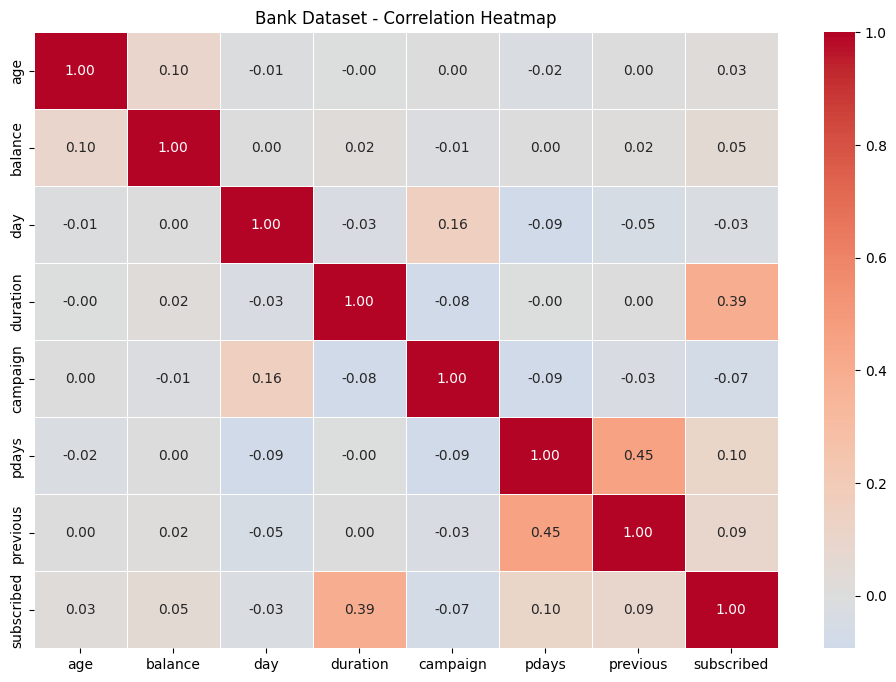

In [18]:
# 6.1. Heatmap yordamida korrelatsiyani ko‘rsatish

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Bank Dataset - Correlation Heatmap')
plt.show()

In [34]:
# 7. Outliersni aniqlash

# Outliers aniqlash uchun ustunlar
columns = ['age', 'balance', 'duration', 'campaign']

outlier_result = {}

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    outlier_result[col] = {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower': lower,
        'Upper': upper,
        'Outliers count': len(outliers)
    }

outlier_df = pd.DataFrame(outlier_result).T

print(outlier_df.round(2))

             Q1      Q3     IQR   Lower   Upper  Outliers count
age        33.0    48.0    15.0    10.5    70.5           487.0
balance    72.0  1428.0  1356.0 -1962.0  3462.0          4729.0
duration  103.0   319.0   216.0  -221.0   643.0          3235.0
campaign    1.0     3.0     2.0    -2.0     6.0          3064.0


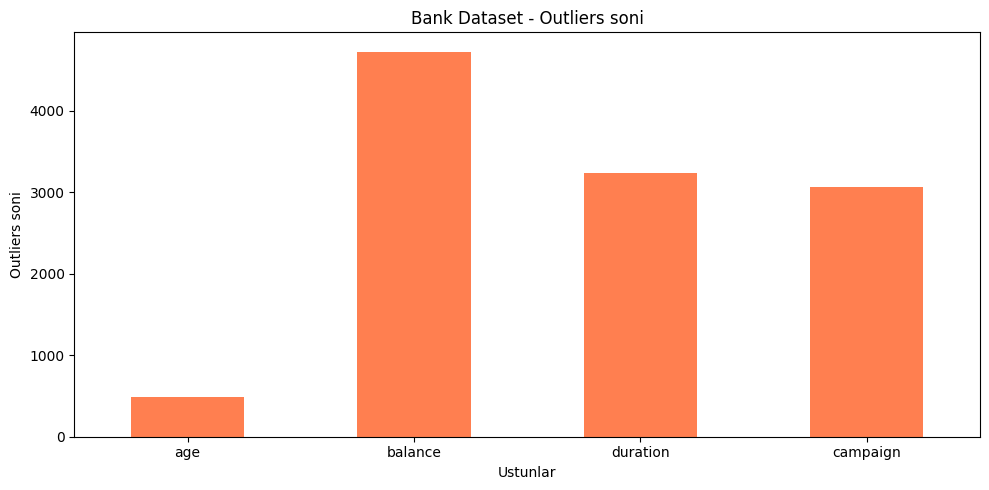

In [33]:
outlier_df['Outliers count'].plot(
    kind='bar',
    figsize=(10, 5),
    color='coral'
)

plt.title('Bank Dataset - Outliers soni')
plt.xlabel('Ustunlar')
plt.ylabel('Outliers soni')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

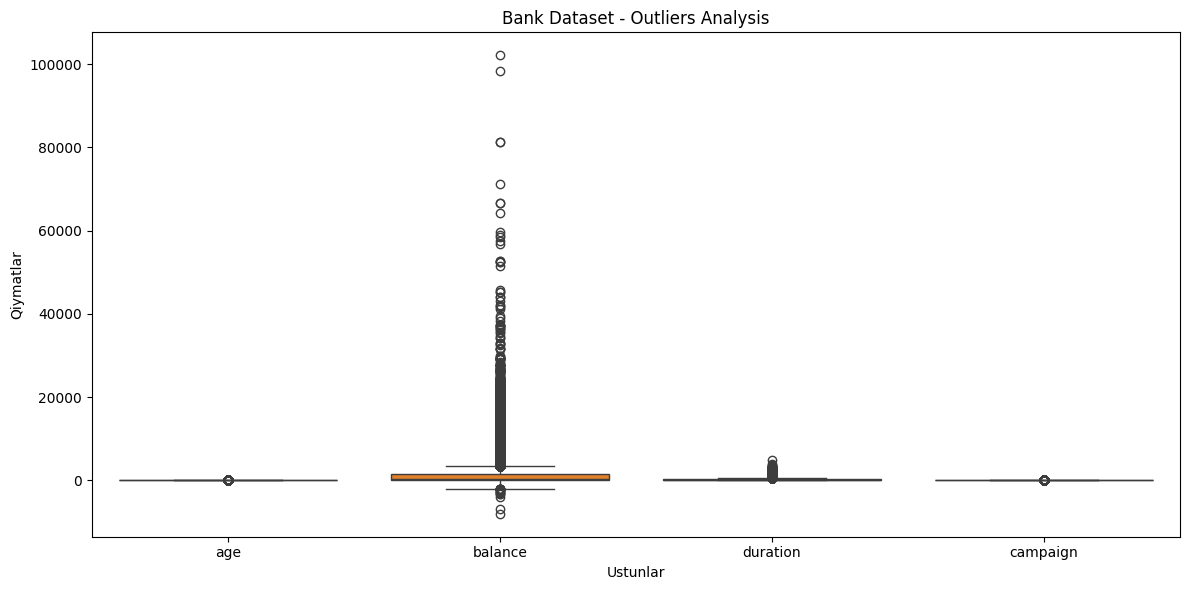

In [35]:
# 8. Boxplot yordamida Outliersni ko‘rish

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[columns])

plt.title('Bank Dataset - Outliers Analysis')
plt.xlabel('Ustunlar')
plt.ylabel('Qiymatlar')

plt.tight_layout()
plt.show()